In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/smart-home-energy-consumption/smart_home_energy_consumption_large.csv


In [2]:
# some useful libraries to import
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme() # apply the default theme
from scipy.stats import normaltest
from scipy.stats import kruskal

# Data loading and preliminary exploration

In [3]:
# the path to reach the dataset
path = '/kaggle/input/smart-home-energy-consumption/smart_home_energy_consumption_large.csv'

# read the dataset
df = pd.read_csv(path)

# the first entries of the dataset
df.head()

,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5


In [4]:
# Dimensions of the dataframe
df.shape

(100000, 8)

In [5]:
# features in the dataset
print(df.columns.tolist())

['Home ID', 'Appliance Type', 'Energy Consumption (kWh)', 'Time', 'Date', 'Outdoor Temperature (°C)', 'Season', 'Household Size']


In [6]:
# there is no NA in the dataset
df.isna().agg(lambda x: sum(x)) # to count NA by feature

Home ID                     0
Appliance Type              0
Energy Consumption (kWh)    0
Time                        0
Date                        0
Outdoor Temperature (°C)    0
Season                      0
Household Size              0
dtype: int64

There is no ``NA`` in the dataset.

In [7]:
home_id = np.unique(df['Home ID']) # retrieve homes id
print('the number of households in the dataset: ',len(home_id))

the number of households in the dataset:  500


In [8]:
# data from the first household
df[df['Home ID'] == home_id[0]].head()

,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size
276,1,Washing Machine,1.65,05:09,2023-09-06,30.7,Summer,4
1022,1,Oven,1.66,01:05,2023-09-06,-7.1,Summer,2
1273,1,Fridge,0.47,11:09,2023-08-04,9.5,Summer,2
1463,1,Microwave,1.63,12:27,2023-03-17,14.8,Winter,2
2122,1,Computer,1.61,23:26,2023-10-24,37.5,Fall,1


In [9]:
# in household '1', data have been collected from 2023-01-05 to 2023-12-31
print('in household 1, data have been collected from ',np.unique(df[df['Home ID'] == home_id[0]]['Date'])[[0,-1]].tolist())

in household 1, data have been collected from  ['2023-01-05', '2023-12-31']


In [10]:
# in household '3', data have been collected from 2023-01-02 to 2023-12-31
print('in household 3, data have been collected from ',np.unique(df[df['Home ID'] == home_id[2]]['Date'])[[0,-1]].tolist())

in household 3, data have been collected from  ['2023-01-02', '2023-12-31']


Data collection days may change by household.

In [11]:
# create the 'Datetime' concatenating 'Date' and 'Time'
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])

# the number of day time data have been collected in the household '1'
print('Number of day time data have been collected in the household 1:',len(np.unique(df[df['Home ID'] == home_id[0]]['Datetime'])))

# the number of day time data have been collected in the household '2'
print('Number of day time data have been collected in the household 2:',len(np.unique(df[df['Home ID'] == home_id[2]]['Datetime'])))

Number of day time data have been collected in the household 1: 211
Number of day time data have been collected in the household 2: 216


The number of date time of data collection may also vary by household.

In [12]:
# a function to retreive the number of day time data have been collected in a household
def numb_day_collect(x): return len(np.unique(df[df['Home ID'] == x]['Datetime']))

# number of day time for data collection in each household
numb_day_collect_inhouse = [numb_day_collect(x) for x in home_id]

print('Min and Max number of day time for household data collection:', np.percentile(numb_day_collect_inhouse, [0, 100]))

print('Mean and Standard error of day time are:', np.mean(numb_day_collect_inhouse), 'and', np.std(numb_day_collect_inhouse).round(2))

Min and Max number of day time for household data collection: [157. 245.]
Mean and Standard error of day time are: 199.95 and 13.86


Households don't have the same number of date time of data collection. The variability within the number of date time in the household is quite important.

In [13]:
# the appliances described in the dataset
np.unique(df['Appliance Type']).tolist()

['Air Conditioning',
 'Computer',
 'Dishwasher',
 'Fridge',
 'Heater',
 'Lights',
 'Microwave',
 'Oven',
 'TV',
 'Washing Machine']

# Data description
The dataset describes $500$ **households** based on seven features that are: 1) the **household size**, i.e. the number of people living in the household, 2) the **appliances** they use, 3) the **energy consumed** by these appliances in 4) **which season**, with 5) what **outdoor temperature**, 6) which **day** and 7) which **time**.

Data collection days and times may change by household, with a quite significant variability within the number of date time data have been collected in the households. These numbers range from $157$ to $245$ with a mean value of $200$ and a standard deviation of $13.86$. The data was collected in 2023, from January to December for all the households. The appliances used in the households are: **Air Conditioning**, **Computer**, **Dishwasher**, **Fridge**, **Heater**, **Lights**, **Microwave**, **Oven**, **TV**, and **Washing Machine**.    

# Preliminary analysis

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

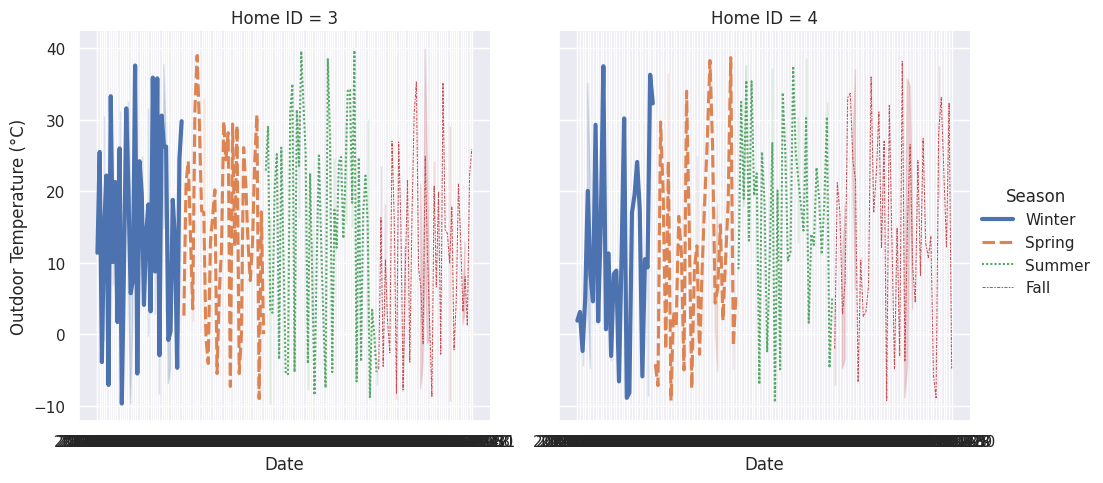

In [14]:
# data from the 3rd and 4th households
df = df.sort_values('Date') # sorting values by 'Date'
df_home3_4 = df[(df['Home ID'] == home_id[2]) | (df['Home ID'] == home_id[3])] 

data = df_home3_4 # the data we want to plot

# plotting temperature per season
sns.relplot(
    data = data,
    x = 'Date', 
    y = 'Outdoor Temperature (°C)',
    col = 'Home ID',
    hue = 'Season',
    style = 'Season',
    kind = 'line',
    size = 'Season',
    facet_kws = dict(sharex = False)
)

The Figure above plots the evolution of the outdoor temperature for the households ``3``and ``4`` by season. It seems to appear that there is no clear effect of the season on the outdoor temperature for these two households. To clarify this for all the households, we could fit, at least, a linear model (for example, a One-way ANOVA) to the data. But first of all, we need to check if the data are drown from a Gaussian distribution.

In [15]:
_, p = normaltest(df['Outdoor Temperature (°C)'])
# interpret results
alpha = 0.05
if p > alpha:
    print("Outdoor temperatures look Gaussian")
else:
    print("Outdoor temperatures don't look Gaussian")

Outdoor temperatures don't look Gaussian


Since the outdoor temperatures are not Gaussian, we have to perform a non parametric test to clarify the season effect on the outdoor temperatures.

In [16]:
# season data
Winter = np.array(df[df['Season'] == 'Winter']['Outdoor Temperature (°C)'])
Spring = np.array(df[df['Season'] == 'Spring']['Outdoor Temperature (°C)'])
Summer = np.array(df[df['Season'] == 'Summer']['Outdoor Temperature (°C)'])
Fall = np.array(df[df['Season'] == 'Fall']['Outdoor Temperature (°C)'])

# Kruskal-Wallis test to check if one of the seasons'effect differs from the others
_, p = kruskal(Winter, Spring, Summer, Fall)

# interpret results
alpha = 0.05
if p > alpha:
    print("Outdoor temperatures have the same distribution per season")
else:
    print("Outdoor temperatures don't have the same distribution per season")

Outdoor temperatures have the same distribution per season


Curiously, the outdoor temperatures are significantly of the same distribution for all the seasons (Winter, Spring, Summer, and Fall). Then, based on the previous analysis, **the seasons don't explain the variability contained in the outdoor temperatures**.

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

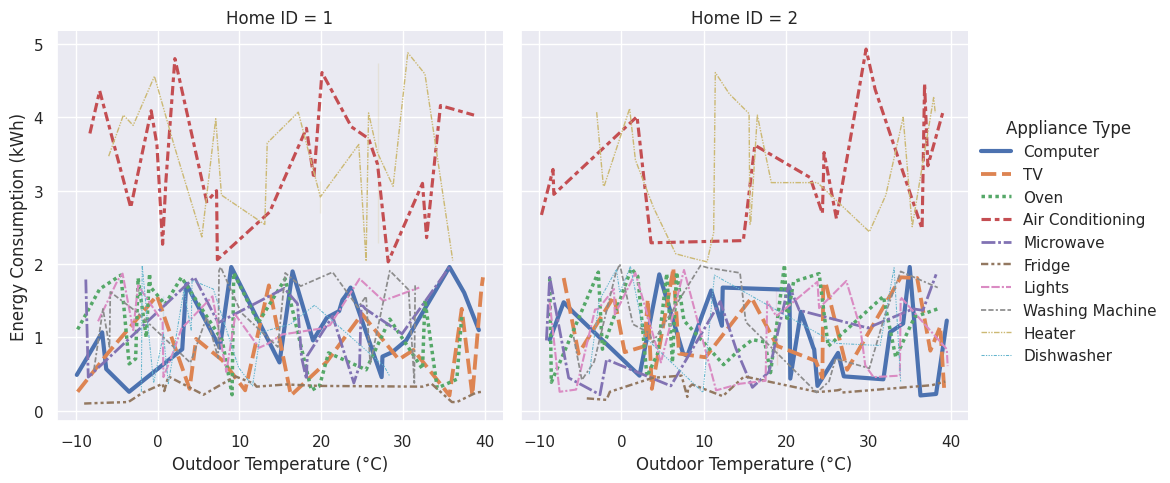

In [17]:
# data from the 1st and 2nd households
df = df.sort_values('Outdoor Temperature (°C)') # sorting values by 'Temperature'
df_home1_2 = df[(df['Home ID'] == home_id[0]) | (df['Home ID'] == home_id[1])] 

data = df_home1_2 # the data we want to plot

# plotting energy consumption per outdoor temperature
sns.relplot(
    data = data,
    x = 'Outdoor Temperature (°C)', 
    y = 'Energy Consumption (kWh)',
    col = 'Home ID',
    hue = 'Appliance Type',
    style = 'Appliance Type',
    kind = 'line',
    size = 'Appliance Type',
    facet_kws = dict(sharex = False)
)

Air conditioning and heaters seem to be the two most consumptive appliances in households, regardless of the outdoor temperatures.

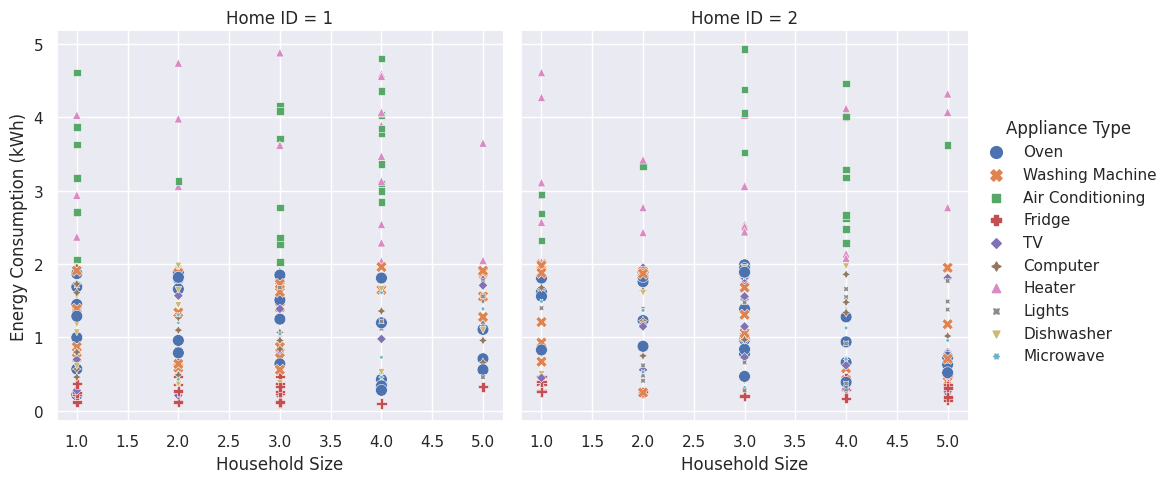

In [18]:
# data from the 1st and 2nd households
df = df.sort_values('Household Size') # sorting values by 'Household Size'
df_home1_2 = df[(df['Home ID'] == home_id[0]) | (df['Home ID'] == home_id[1])] 

data = df_home1_2 # the data we want to plot

# plotting energy consumption per household size
sns.relplot(
    data = data,
    x = 'Household Size', 
    y = 'Energy Consumption (kWh)',
    col = 'Home ID',
    hue = 'Appliance Type',
    style = 'Appliance Type',
#    kind = 'line',
    size = 'Appliance Type',
    facet_kws = dict(sharex = False)
)

Air conditioning and heaters seem to remain the most consumptive appliances in the household regardless of the household's size.

Now, let's see the behavior of the mean energy consumption of the appliances, regardless of the household.

In [19]:
# compute the mean value for energy consumption, outdoor temperature and 
# household size for each appliance per season in each household
df_mean = df.sort_values('Datetime').groupby(['Home ID','Season','Appliance Type'])[['Energy Consumption (kWh)','Outdoor Temperature (°C)','Household Size']].agg(lambda x: np.mean(x))

# rename the columns to be clear
df_mean = df_mean.rename(columns={'Energy Consumption (kWh)':'Mean Energy Consumption (kWh)',
                       'Outdoor Temperature (°C)':'Mean Outdoor Temperature (°C)',
                       'Household Size':'Mean Household Size'})

df_mean.head()

Mean Energy Consumption (kWh)  \
Home ID Season Appliance Type                                    
1       Fall   Air Conditioning                       3.210000   
               Computer                               0.982857   
               Dishwasher                             1.046667   
               Fridge                                 0.254286   
               Lights                                 1.250000   

                                 Mean Outdoor Temperature (°C)  \
Home ID Season Appliance Type                                    
1       Fall   Air Conditioning                      19.220000   
               Computer                              22.100000   
               Dishwasher                             2.400000   
               Fridge                                17.728571   
               Lights                                 4.850000   

                                 Mean Household Size  
Home ID Season Appliance Type                         
1       Fall   Air Conditioning             2.600000  
               Computer                     2.285714  
               Dishwasher                   2.000000  
               Fridge                       2.285714  
               Lights                       3.833333

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


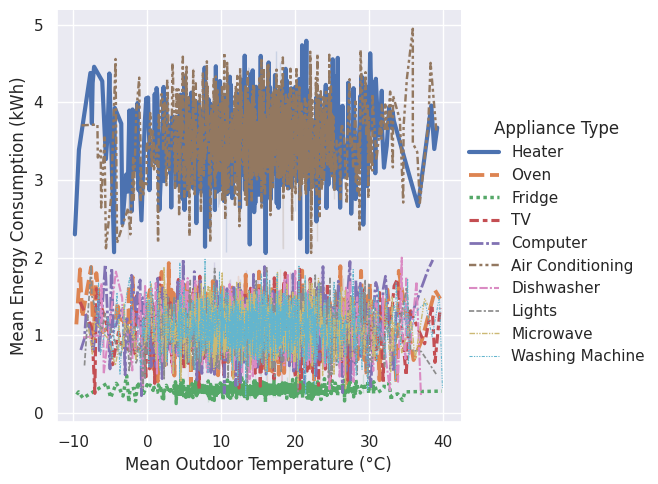

In [20]:
# data from all households
df_mean = df_mean.sort_values('Mean Outdoor Temperature (°C)') # sorting values by 'Temperature'

data = df_mean[::2] # the data we want to plot

# plotting mean energy consumption per mean temperature
sns.relplot(
    data = data,
    x = 'Mean Outdoor Temperature (°C)', 
    y = 'Mean Energy Consumption (kWh)',
    hue = 'Appliance Type',
    style = 'Appliance Type',
    kind = 'line',
    size = 'Appliance Type',
    facet_kws = dict(sharex = False)
)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


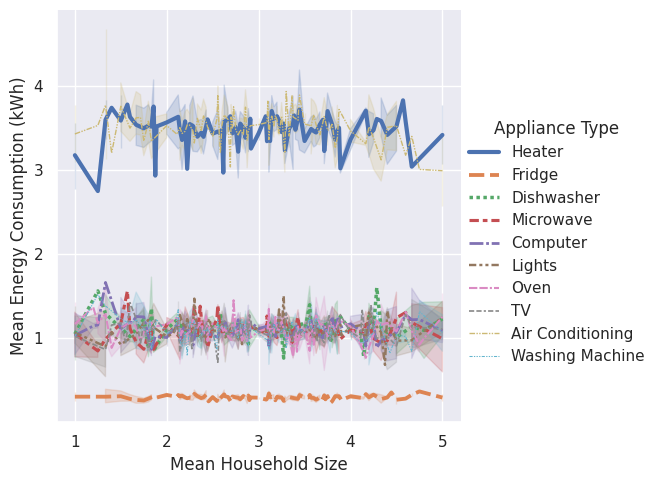

In [21]:
# data from all households
df_mean = df_mean.sort_values('Mean Household Size') # sorting values by 'Household Size'

data = df_mean[::2] # the data we want to plot

# plotting mean energy consumption per mean temperature
sns.relplot(
    data = data,
    x = 'Mean Household Size', 
    y = 'Mean Energy Consumption (kWh)',
    hue = 'Appliance Type',
    style = 'Appliance Type',
    kind = 'line',
    size = 'Appliance Type',
    facet_kws = dict(sharex = False)
)

The last two Figures plot the curve of the mean energy consumption of appliances conditional on the mean outdoor temperature and the mean household size respectively. These Figures confirm that Air conditioning and heaters are the most consumptive appliances. It appears in these Figures that fridges are the least consumptive appliances.

In [22]:
# Fitting a regression model to the mean data,
# attempting to explain the energy consumption by 
# household size and the outdoor temperature.

# reg_model = smf.ols('Mean Energy Consumption (kWh) ~ Mean Outdoor Temperature (°C) + Mean Household Size', data=df_mean)

# Preliminary analysis results
Preliminary analysis of the data show that:
- The seasons do not affect the variation of the outdoor temperature.
- The most consumptive energy appliances are air conditioning and heaters.
- The least consumptive energy appliances are fridges.

In the next session, by using a Generative AI, we will confirm the preliminary analysis results. We also will address the following questions:
- What are the most three consumptive appliances when the outdoor temperature is negative?
- Are these appliances still the most consumptive when the outdoor temperature is above 10°?
- Between the outdoor temperature and the household size, which one explains better the energy consumption of the appliances?